<a href="https://colab.research.google.com/github/stanisicsrdjan777-a11y/message/blob/main/Breast_Ultrasound_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset URL: https://www.kaggle.com/datasets/aryashah2k/breast-ultrasound-images-dataset
License(s): CC0-1.0
100% 195M/195M [00:12<00:00, 16.3MB/s]

✅ Dataset spreman
🧹 Obrisano oštećenih slika: 0
Found 625 images belonging to 3 classes.
Found 155 images belonging to 3 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.4208 - loss: 0.3506 - val_accuracy: 0.6258 - val_loss: 0.0937
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 334ms/step - accuracy: 0.5600 - loss: 0.2456 - val_accuracy: 0.5935 - val_loss: 0.0975
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 332ms/step - accuracy: 0.5744 - loss: 0.2172 - val_accuracy: 0.5871 - val_loss: 0.1125
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 351ms/step - accuracy: 0.6112 - loss: 0.1931 - val_accuracy: 0.6581 - val_loss: 0.1010
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 353ms/step - accuracy: 0.6032 - loss: 0.1991 - val_accuracy: 0.6645 - val_loss: 0.1025
Epoch 6/12
40/40 ━━━━━━━━━━━

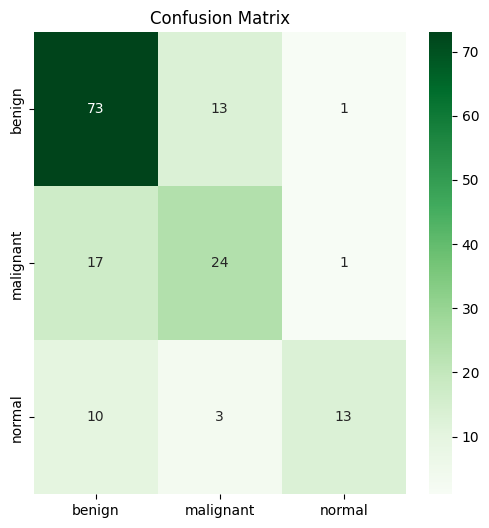

/usr/local/lib/python3.12/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6a94b6fb84899b1546.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ==========================================================
# AI MODEL FOR BREAST ULTRASOUND CLASSIFICATION
# EfficientNetB0 + Focal Loss + Fine-Tuning + Gradio
# ==========================================================

# Install required libraries:
# kaggle     -> download the dataset from Kaggle
# tensorflow -> build and train the model
# gradio     -> create a simple web demo
# --quiet    -> reduce install output
!pip install kaggle tensorflow gradio --quiet


# ==========================================================
# IMPORTS
# ==========================================================

import os
import glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import userdata
from PIL import Image, ImageFile
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

import gradio as gr


# ==========================================================
# REPRODUCIBILITY
# ==========================================================

# Fix random seeds so results are more repeatable across runs.
tf.random.set_seed(42)
np.random.seed(42)


# ==========================================================
# KAGGLE API SETUP
# ==========================================================

# Read credentials from Colab Secrets (safer than hardcoding).
username = userdata.get("KAGGLE_USERNAME")
key = userdata.get("KAGGLE_API_TOKEN")

# Kaggle expects credentials in ~/.kaggle/kaggle.json
os.makedirs("/root/.kaggle", exist_ok=True)
with open("/root/.kaggle/kaggle.json", "w") as f:
    f.write(f'{{"username":"{username}","key":"{key}"}}')

# Restrict permissions so only the owner can read the file.
os.chmod("/root/.kaggle/kaggle.json", 600)


# ==========================================================
# DOWNLOAD DATASET
# ==========================================================

# Download and unzip the BUSI breast ultrasound dataset.
!kaggle datasets download -d aryashah2k/breast-ultrasound-images-dataset -p /content --unzip

data_dir = "/content/Dataset_BUSI_with_GT"

# Remove mask images. We only need the original ultrasound images for classification.
for folder in ["benign", "malignant", "normal"]:
    folder_path = os.path.join(data_dir, folder)
    for file in os.listdir(folder_path):
        if "mask" in file.lower():
            os.remove(os.path.join(folder_path, file))

print("Dataset ready")


# ==========================================================
# REMOVE CORRUPTED IMAGES
# ==========================================================

# Allow loading of truncated images so one bad file does not crash training.
ImageFile.LOAD_TRUNCATED_IMAGES = True

removed = 0
for root, dirs, files in os.walk(data_dir):
    for file in files:
        file_path = os.path.join(root, file)
        try:
            img = Image.open(file_path)
            img.verify()
        except Exception:
            os.remove(file_path)
            removed += 1

print(f"Removed corrupted images: {removed}")


# ==========================================================
# DATA GENERATORS AND AUGMENTATION
# ==========================================================

# Training generator with light augmentation.
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.08,
    horizontal_flip=True,
    validation_split=0.2,
)

# Validation generator without augmentation.
val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2,
)

train_generator = train_datagen.flow_from_directory(
    data_dir,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    subset="training",
    shuffle=True,
)

val_generator = val_datagen.flow_from_directory(
    data_dir,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
)


# ==========================================================
# CLASS WEIGHTS
# ==========================================================

# Balance the three classes (benign / malignant / normal) if the dataset is imbalanced.
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_generator.classes),
    y=train_generator.classes,
)
class_weight_dict = dict(enumerate(class_weights))


# ==========================================================
# MODEL — TRANSFER LEARNING
# ==========================================================

# Load EfficientNetB0 pretrained on ImageNet, without the original classifier.
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
)

# Freeze the base model for the first training phase.
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
x = Dense(512, activation="relu")(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
outputs = Dense(3, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=outputs)


# ==========================================================
# FOCAL LOSS
# ==========================================================

def focal_loss(gamma=2.0, alpha=0.25):
    """Focal loss to focus training on harder examples."""
    def loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        cross_entropy = -y_true * tf.math.log(y_pred)
        weight = alpha * tf.pow(1.0 - y_pred, gamma)
        return tf.reduce_mean(tf.reduce_sum(weight * cross_entropy, axis=1))
    return loss


# ==========================================================
# COMPILE — PHASE 1 (HEAD ONLY)
# ==========================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=focal_loss(),
    metrics=["accuracy"],
)

callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=7, restore_best_weights=True),
    ModelCheckpoint("best_model.keras", monitor="val_accuracy", save_best_only=True),
]


# ==========================================================
# TRAIN — PHASE 1
# ==========================================================

history1 = model.fit(
    train_generator,
    epochs=12,
    validation_data=val_generator,
    class_weight=class_weight_dict,
    callbacks=callbacks,
)


# ==========================================================
# FINE-TUNING — PHASE 2
# ==========================================================

# Unfreeze the base model, then freeze all but the last 80 layers.
base_model.trainable = True
for layer in base_model.layers[:-80]:
    layer.trainable = False

# Recompile with a much smaller learning rate for fine-tuning.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=focal_loss(),
    metrics=["accuracy"],
)

history2 = model.fit(
    train_generator,
    epochs=25,
    validation_data=val_generator,
    class_weight=class_weight_dict,
    callbacks=callbacks,
)


# ==========================================================
# EVALUATION
# ==========================================================

val_generator.reset()
pred = model.predict(val_generator, verbose=0)
y_pred = np.argmax(pred, axis=1)
y_true = val_generator.classes

print("FINAL EVALUATION")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=list(train_generator.class_indices.keys()),
    )
)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=train_generator.class_indices.keys(),
    yticklabels=train_generator.class_indices.keys(),
    cmap="Greens",
)
plt.title("Confusion Matrix")
plt.show()


# ==========================================================
# GRADIO DEMO
# ==========================================================

def predict_cancer(image):
    """Run a single ultrasound image through the model and return the prediction."""
    image_resized = image.resize((224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(image_resized)
    img_array = preprocess_input(img_array)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)
    class_names = list(train_generator.class_indices.keys())
    cls = class_names[np.argmax(prediction)]
    confidence = float(np.max(prediction) * 100)

    return f"{cls.upper()} — Confidence: {confidence:.2f}%"


# Example images for the Gradio interface (2 per class).
examples = [
    [p]
    for p in (
        glob.glob(os.path.join(data_dir, "benign", "*.png"))[:2]
        + glob.glob(os.path.join(data_dir, "malignant", "*.png"))[:2]
        + glob.glob(os.path.join(data_dir, "normal", "*.png"))[:2]
    )
]

interface = gr.Interface(
    fn=predict_cancer,
    inputs=gr.Image(type="pil"),
    outputs=gr.Textbox(label="AI Prediction"),
    examples=examples,
    title="AI Breast Ultrasound Classification",
    description="EfficientNetB0 + Focal Loss + Fine-Tuning",
    theme="soft",
)

# share=True creates a public link you can send to others.
interface.launch(share=True)
